**Experimento anterior.** La campana con seleccion interna separada y regularizacion se muestra en [el notebook 03](03_regularizacion_validacion.ipynb).

# Partición fija: entrenamiento hasta 2017 y validación 2018–2022

18 ajustes completados en 257.4 segundos acumulados de entrenamiento en CPU. Un ajuste por arquitectura, variante y semilla; los mismos pesos se usan para todos los años. Máximo 40 épocas, paciencia 10. No se ha ejecutado una nueva búsqueda de Optuna.

Estas métricas pertenecen a la validación usada para seleccionar la época y comparar candidatos; no son resultados de un test independiente. El test 2023–2024 sigue reservado. Las cifras son medias de métricas de tres semillas, no métricas de una predicción promediada.

[Vista HTML](../experiments/fixed_split_2017_2022/report/comparacion.html). Las figuras de comparación usan la semilla 42. Este notebook solo lee los resultados guardados; no entrena ni abre el test.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'experiments/fixed_split_2017_2022/report/validation_means.csv').is_file())
REPORT = ROOT / 'experiments/fixed_split_2017_2022/report'
display(pd.read_csv(REPORT / 'validation_means.csv'))

,architecture,variant,horizon,n,seeds,rmse_std,mae,mse,rmse,r2,relative_rmse,relative_rmse_vs_future
0,GRU,levels,5,1263,3,0.024919,3.984725,33.062939,5.750002,0.926135,1.008312,1.196773
1,GRU,levels,63,1205,3,0.342151,10.431728,234.405042,15.307743,0.499574,0.957517,1.032199
2,GRU,levels,252,1020,3,0.211584,15.722503,372.967816,19.311602,0.313373,0.700269,0.717015
3,GRU,signals,5,1263,3,0.050755,3.574830,24.869589,4.986770,0.944440,0.874472,1.037918
4,GRU,signals,63,1205,3,0.419055,10.565046,211.114859,14.525763,0.549295,0.908603,0.979471
5,GRU,signals,252,1020,3,0.457795,17.331393,437.344220,20.909436,0.194858,0.758209,0.776340
6,LSTM,levels,5,1263,3,0.008401,3.989121,32.311801,5.684343,0.927813,0.996798,1.183107
7,LSTM,levels,63,1205,3,0.108017,11.303540,245.929255,15.681884,0.474971,0.980920,1.057428
8,LSTM,levels,252,1020,3,0.304888,20.671116,607.636649,24.649030,-0.118648,0.893813,0.915187
9,LSTM,signals,5,1263,3,0.019466,4.016064,32.702853,5.718619,0.926940,1.002808,1.190241


## Comparación de todas las redes y horizontes

Eje horizontal: fecha objetivo. Cada punto corresponde a un origen distinto. Los pesos no cambian por año.

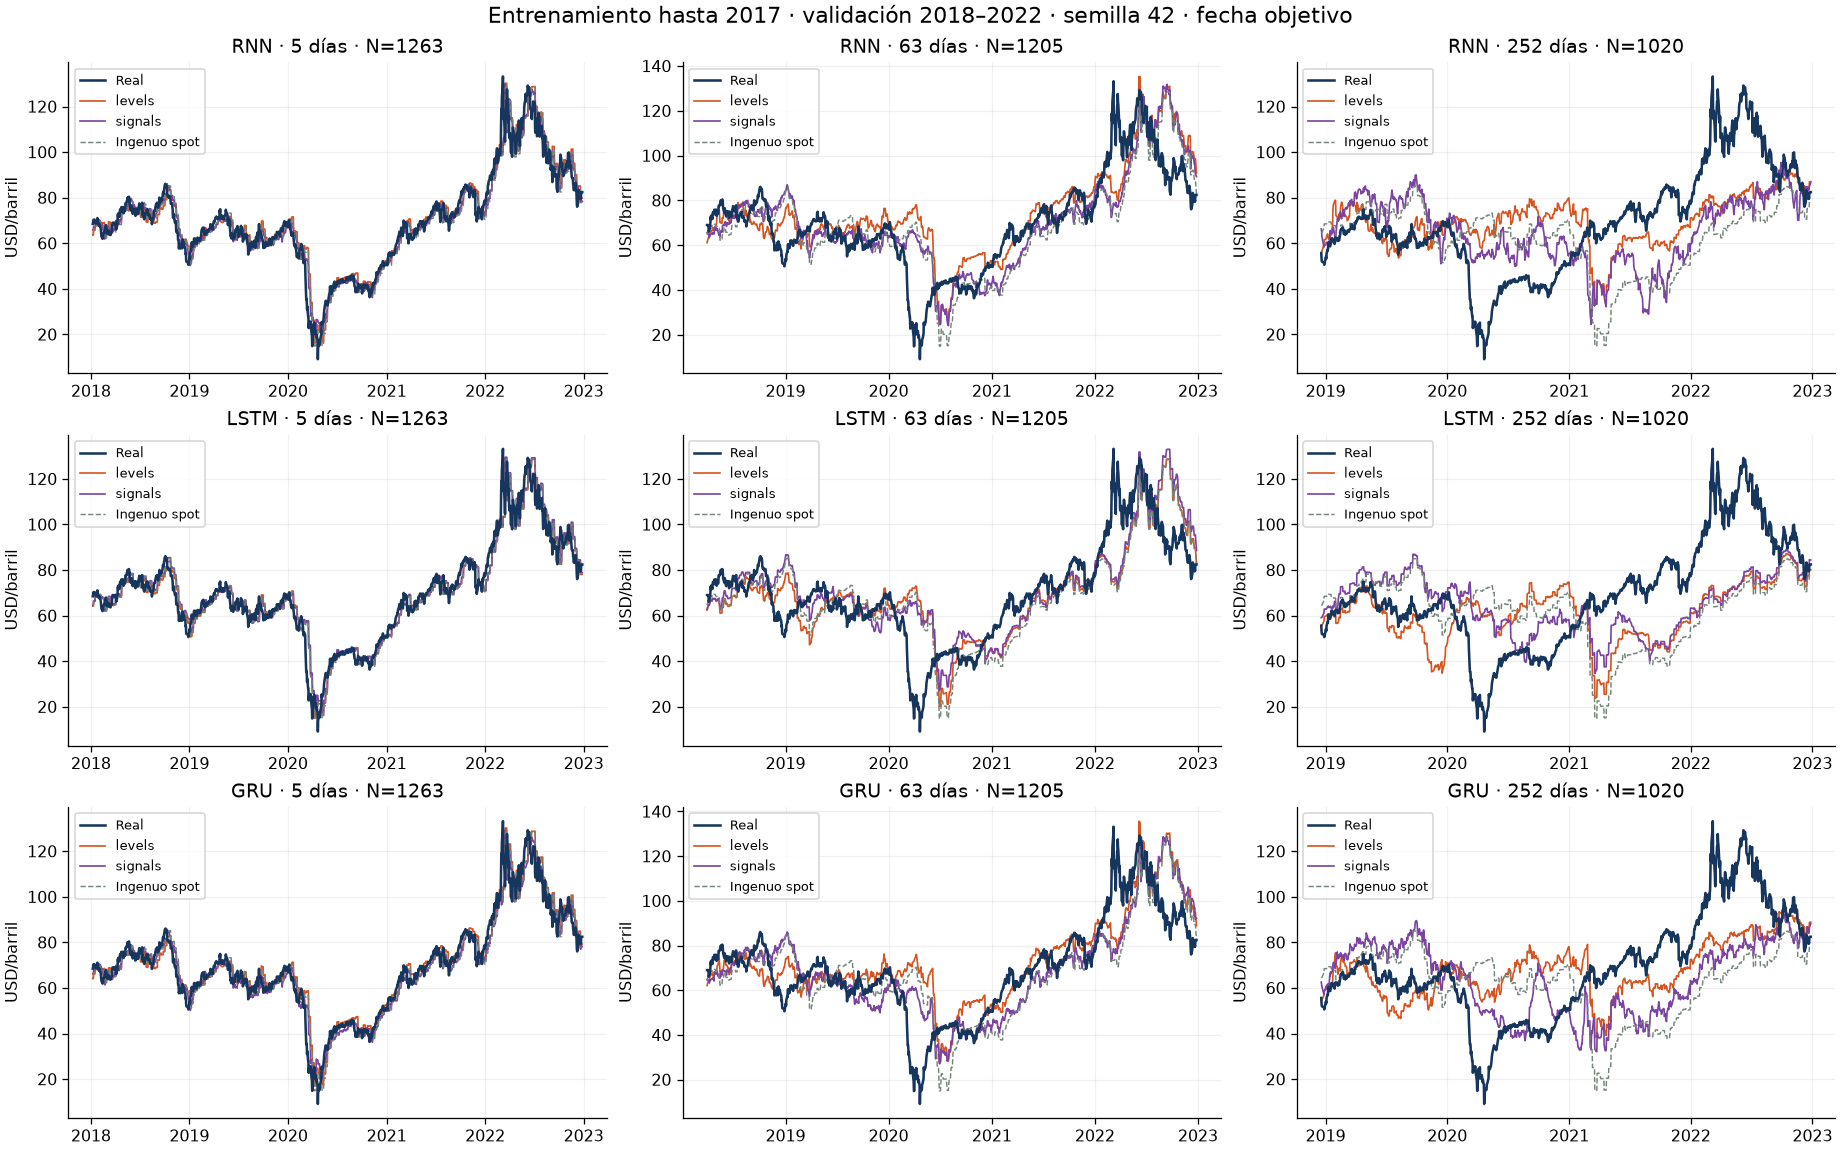

In [2]:
display(Image(filename=str(REPORT / '01_comparacion_completa.png')))

## Precio real y predicho del candidato con menor ratio medio

Eje horizontal: fecha objetivo. Cada punto corresponde a un origen distinto. Los pesos no cambian por año.

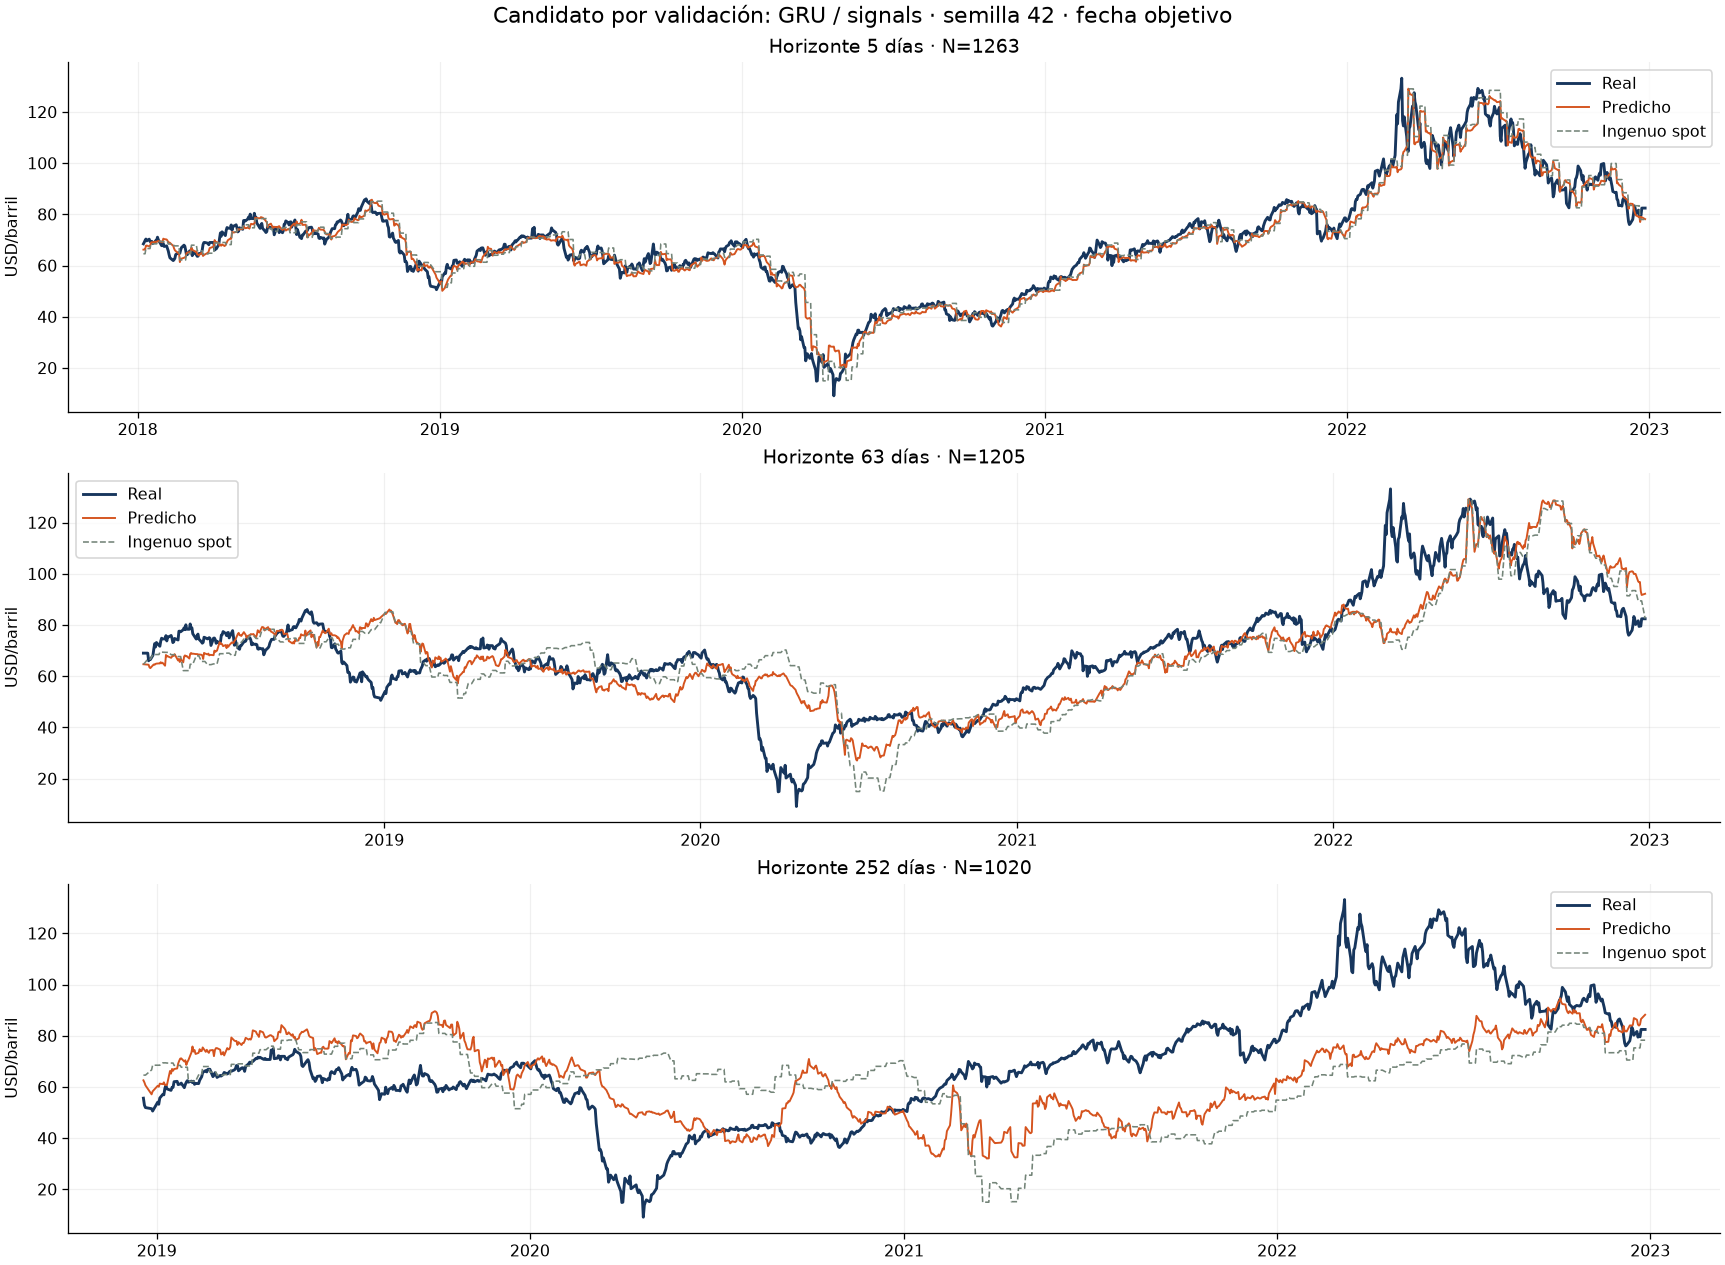

In [3]:
display(Image(filename=str(REPORT / '02_detalle_candidato.png')))

## Pérdida de entrenamiento y validación

La regla diagnóstica detecta señal de sobreajuste en 5 de 18 ajustes: la pérdida de entrenamiento baja y el ratio de validación empeora más del 2% desde la época elegida hasta el final. Se conservan los pesos de la época elegida. Este indicador no demuestra que el sobreajuste esté eliminado; las diferencias de régimen entre 2012–2017 y 2018–2022 también afectan a las pérdidas.

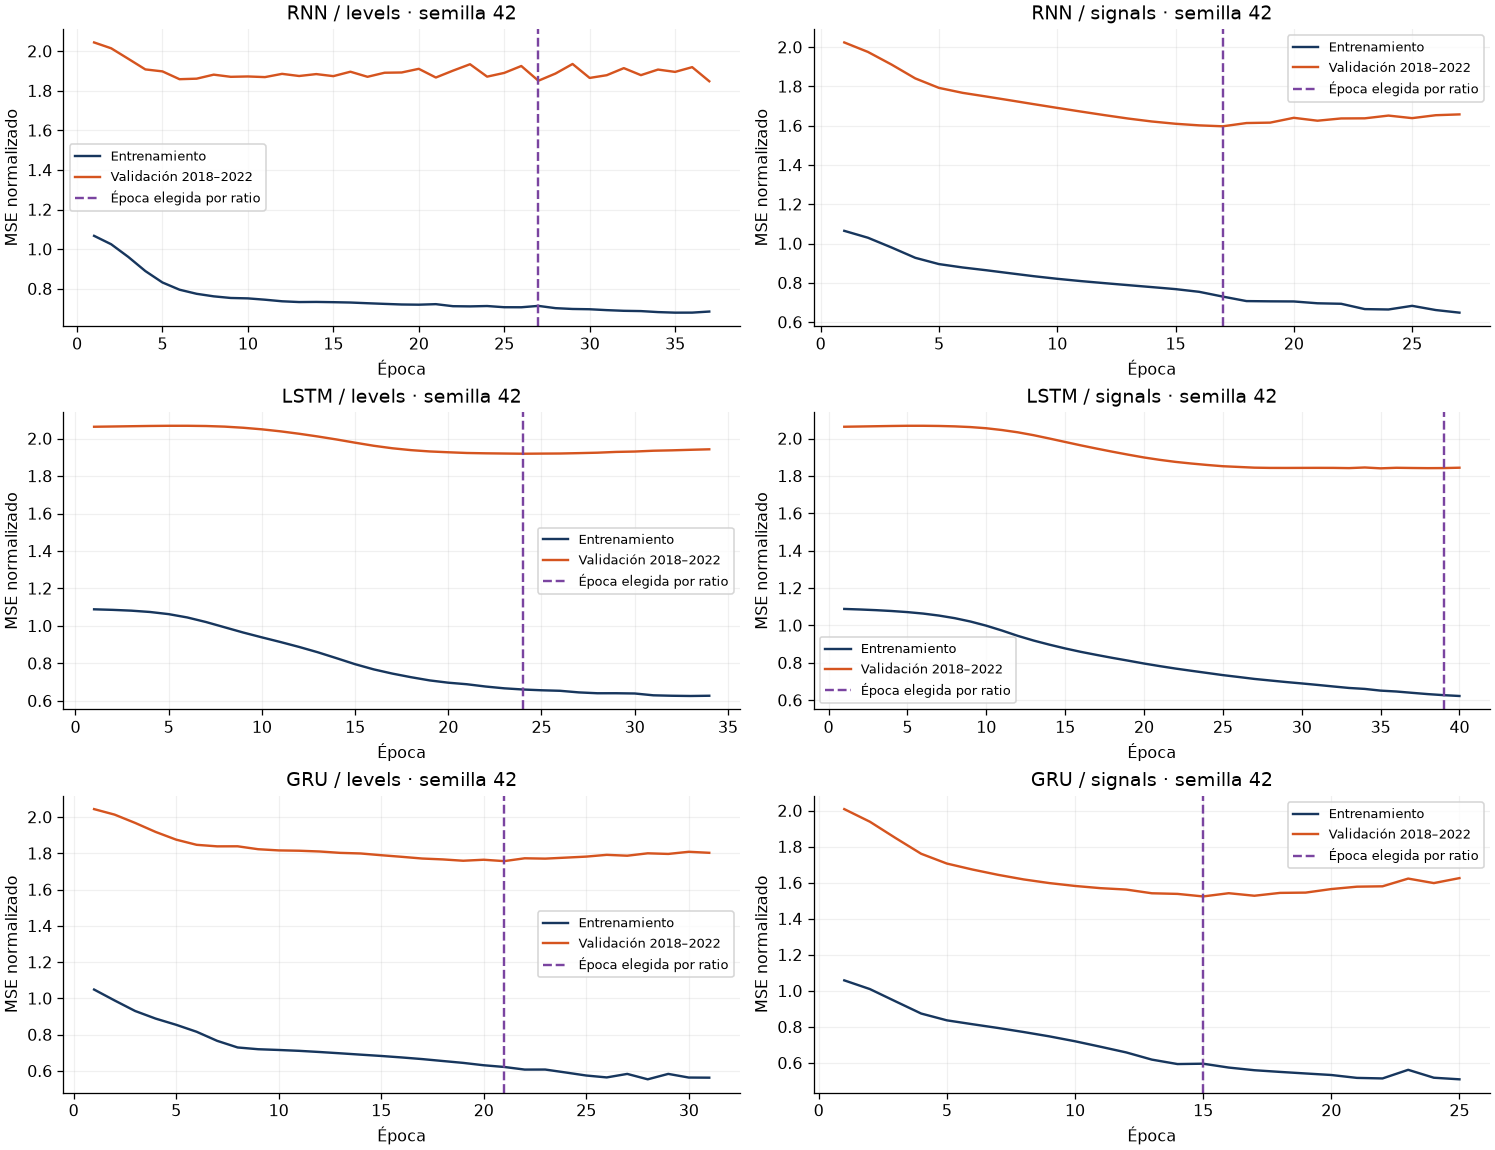

In [4]:
display(Image(filename=str(REPORT / '03_curvas_entrenamiento.png')))